**Database description:**
* Survived: Выжил (1) или умер (0)
* Pclass: класс пассажира.
* Name: имя пассажира.
* Sex: пол пассажира.
* Age: возраст пассажира.
* SibSp: количество братьев и сестер/супругов на борту.
* Parch: количество родителей/детей на борту.
* Ticket: номер билета.
* Fare: Тариф
* Cabin: Кабина
* Embarked: Порт посадки

[Более подробная информация на сайте kaggle](https://www.kaggle.com/c/titanic/data)

**Импортирование основных библиотек**

In [1]:
#Data EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import eli5
import phik
#Preprocessing ML
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split, 
    RandomizedSearchCV, 
    KFold, 
    cross_validate
)
from sklearn.impute import SimpleImputer
#Models
from sklearn.linear_model import (
    LogisticRegression, 
    RidgeClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import (
    RandomForestClassifier, 
    ExtraTreesClassifier, 
    GradientBoostingClassifier,
    StackingClassifier
)
#ELSE
import sklearn
from cycler import cycler
import warnings
import shutil

**Константы**

In [2]:
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
TEST_SIZE = 0.1
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

#colors
colormap = sns.diverging_palette(220, 10, as_cmap = True)
colorbox = [
    "#fb4934",  # Красный
    "#fabd2f",  # Желтый
    "#b8bb26",  # Зеленый
    "#83a598",  # Голубой
    "#d3869b",  # Фиолетовый
    "#fe8019",  # Ораньжевый
    "#8ec07c",  # Бирюзовый
]

rc = {
    # Цвет фона внутри графиков (область данных)
    "axes.facecolor": "#282828",  # тёмно-серый

    # Цвет фона всей фигуры (вокруг графика)
    "figure.facecolor": "#282828",  # тот же тёмно-серый
    
    # Цвет рамки вокруг графика
    "axes.edgecolor": "#3c3836",  # чуть светлее серый
    
    # Цвет сетки на графике
    "grid.color": "#504945",  # средне-серый, контрастный на фоне
    
    # Цвет подписей осей (xlabel, ylabel)
    "axes.labelcolor": "#ebdbb2",  # светло-бежевый, хорошая читаемость
    
    # Цвет делений и подписей на оси X
    "xtick.color": "#d5c4a1",  # бежевый
    
    # Цвет делений и подписей на оси Y  
    "ytick.color": "#d5c4a1",  # бежевый (тот же что и для X)
    
    # Прозрачность сетки (0 = невидима, 1 = полностью непрозрачна)
    "grid.alpha": 0.3,  # 30% непрозрачности, лёгкая сетка
    
    # Цикл цветов для автоматической подстановки
    # (каждая новая линия/столбец берёт следующий цвет из colorbox)
    "axes.prop_cycle": cycler(color=colorbox),
    
    # Цвет фона легенды
    "legend.facecolor": "#DCDCDC",  # светло-серый (почти белый)
    
    #Цвет текста изменяется на светло-бежевый
    "text.color": "ebdbb2", 
    
    # 3. Цвет заголовка графика
    "axes.titlecolor": "white",
    
    # 4. Цвет делений на осях
    "xtick.color": "white",
    "ytick.color": "white",
    
    # 5. Цвет легенды
    "legend.labelcolor": "white",
    "legend.title_fontsize": 12,
}

# 4. ПРИМЕНЕНИЕ НАСТРОЕК
sns.set(rc=rc, style="darkgrid")
# Устанавливаем наш словарь rc и стиль "darkgrid" seaborn
# darkgrid добавляет сетку на тёмный фон (есть также whitegrid, dark, white)


palette_sex={"female" : "#c90076", "male": "#2986CC"}
palette_surv = {0: "#00ffff", 1: "#ff0000"}

**Функции**

In [3]:
#Функция для визуализации EDA графиков: гистограмма, boxplot
def num_plot(data,column_list,bins=50,figsize=(6,3),target='survived'):
    for column in column_list:
        plt.figure(figsize=(figsize))
        # Первый subplot - ГИСТОГРАММА
        plt.subplot(1,2,1)
        sns.histplot(data=data,x=column,kde=True,bins=bins, hue=target, palette=colorbox, alpha=0.7)
        plt.title(f'Гистограмма частоты {column} относительно целевой переменной',color='white')
        plt.xlabel(f'Значения {column}',color='white')
        plt.ylabel('Частота',color='white')
        plt.grid()
        # Второй subplot - BOXPLOT
        plt.subplot(1,2,2)
        sns.boxplot(data=data,y=column, hue='survived', palette=colorbox)
        plt.title(f'Boxplot {column}',color='white')
        plt.xlabel('Boxplot',color='white')
        plt.ylabel('Значения',color='white')
        plt.grid()
        plt.show()

#Функция визуализации pie charm
def pie_charm(values,index,title='',colors=[colorbox[0],colorbox[1]]):
    plt.figure(figsize=(14, 7))
    plt.pie(
        values,
        labels=index,
        startangle=90, frame=True, radius=1.3,
        wedgeprops={'linewidth': 1, 'edgecolor': 'white'},
        textprops={'fontsize': 12, 'weight': 'bold'},
        autopct='%1.1f%%',
        colors=colors,
    )
    plt.legend()
    plt.title(title,color='white')
    plt.show()

#Функция для визуализации EDA графиков: countplot
def count_plot(data,column_list,figsize=(9,3),palette=colorbox):
    for column in column_list:
        plt.figure(figsize=figsize)
        sns.countplot(data=data,x=column,palette=colorbox)
        plt.title(f'Количество {column}',color='white')
        plt.xlabel('Значения',color='white')
        plt.ylabel('Количество значений',color='white')
        plt.xticks(fontsize=7,rotation=90)
        plt.show()

#Функция визуализации линейной зависимости
def plotlm(x_var, y_var, row_var=None):
    lm = sns.lmplot(
        data=df_train,
        x=x_var,
        y=y_var,
        row=row_var,
        hue = row_var,
        lowess=True,
        height=2,
        aspect=4,
        palette=palette_sex ,
        col="survived",
        line_kws={"color": "#23272a"},
        scatter_kws={"alpha": 0.3},
    )
    for ax in lm.axes.flatten():
        ax.tick_params(color='white')
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")

        lm.set_titles(
            col_template="Target value:{col_name}",
            color="white",
            size=12,
            weight="bold"
    )

    plt.suptitle(
        f"{x_var.replace('_', ' ').title()} VS {y_var.replace('_', ' ').title()} by Target Variable",
        y=1.02,
        fontsize=16,color='white',
    )
    
    plt.show()

#Обработка пропусков и создание новых признаков
def preproc_and_feature_engineering (data):
    data['fare'].fillna(data['fare'].median(), inplace=True)
    
    data['title'] = data['name'].str.split(',').str[1].str.split('.').str[0]
    data['title'] = (
    data['title']
        .astype(str)
        .str.replace(r'[\u200b\u00a0]', '', regex=True)
        .str.replace(r'\s+', '', regex=True)
        .str.normalize('NFKD')
        .str.strip()
    )
    data['title'] = data['title'].replace(['Countess', 'Dona','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer'], 'Rare')
    data['title'] = data['title'].replace(['Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer'], 'Rare')
    data['title'] = data['title'].replace(['Mlle', 'Ms','Lady'], 'Miss')
    data['title'] = data['title'].replace('Mme', 'Mrs')
    
    data['cabin_location'] = data['cabin'].str[0]
    data['cabin_location'].fillna('U', inplace=True)
    data['cabin_count'] = data['cabin'].apply(lambda x: len(x.split(',')) if pd.notnull(x) else 0)
    data['has_cabin'] = (data['cabin'].notna()).astype('int')

    age_by_title = data.groupby('title')['age'].median()
    
    data['age'] = data['age'].fillna(data['title'].map(age_by_title))
    data['age_cat'] = pd.cut(data['age'],bins = [0, 12, 18, 60, 120],labels=['Child', 'Teen', 'Adult', 'Senior'])
    data['embarked'].fillna('U', inplace=True)
    data['fare'].fillna(data['fare'].median())
    
    data['family_size'] = data['parch'] + data['sibsp'] + 1
    data['ticket_group_size'] = data['ticket'].map(data['ticket'].value_counts())
    data['fare_deviation'] = data['fare'] - data['pclass'].map(data.groupby('pclass')['fare'].median())

## Первичный анализ данных

In [4]:
df_train_raw = pd.read_csv("C:/Users/user/datasets/titanic/train.csv")

In [5]:
df_train_raw.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df_train_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df_train_raw.duplicated().sum()

0

Данные об пассажирах "Титаника" были успешно загружены. Содержание датасета соответствует описанию. Столбец хранящий информацию о возрасте пассажиров определен как непрерывный (тип: float), необходимо разобраться в причине такого поведения данных и преобразовать тип float в int. Также были выявлены пустые значения в следующих столбцах:
* Age - 177
* Cabin - 687
* Embarked - 2


Наименования признаков содержат несколько последовательных заглавных букв. Для удобства обращения к столбцам и соблюдения правил pep8, названия всех признаков будут переименованы в единый формат. Дубликаты не обнаружены.

In [5]:
df_test_raw = pd.read_csv("C:/Users/user/datasets/titanic/test.csv")

In [9]:
df_test_raw.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [10]:
df_test_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [11]:
df_test_raw.duplicated().sum()

0

Аналогичнно тренировочной выборке, тестовая выборка содержит те же проблемы, но дополнительно было обнаружено 1 пропущенное значение в признаке "Fare".

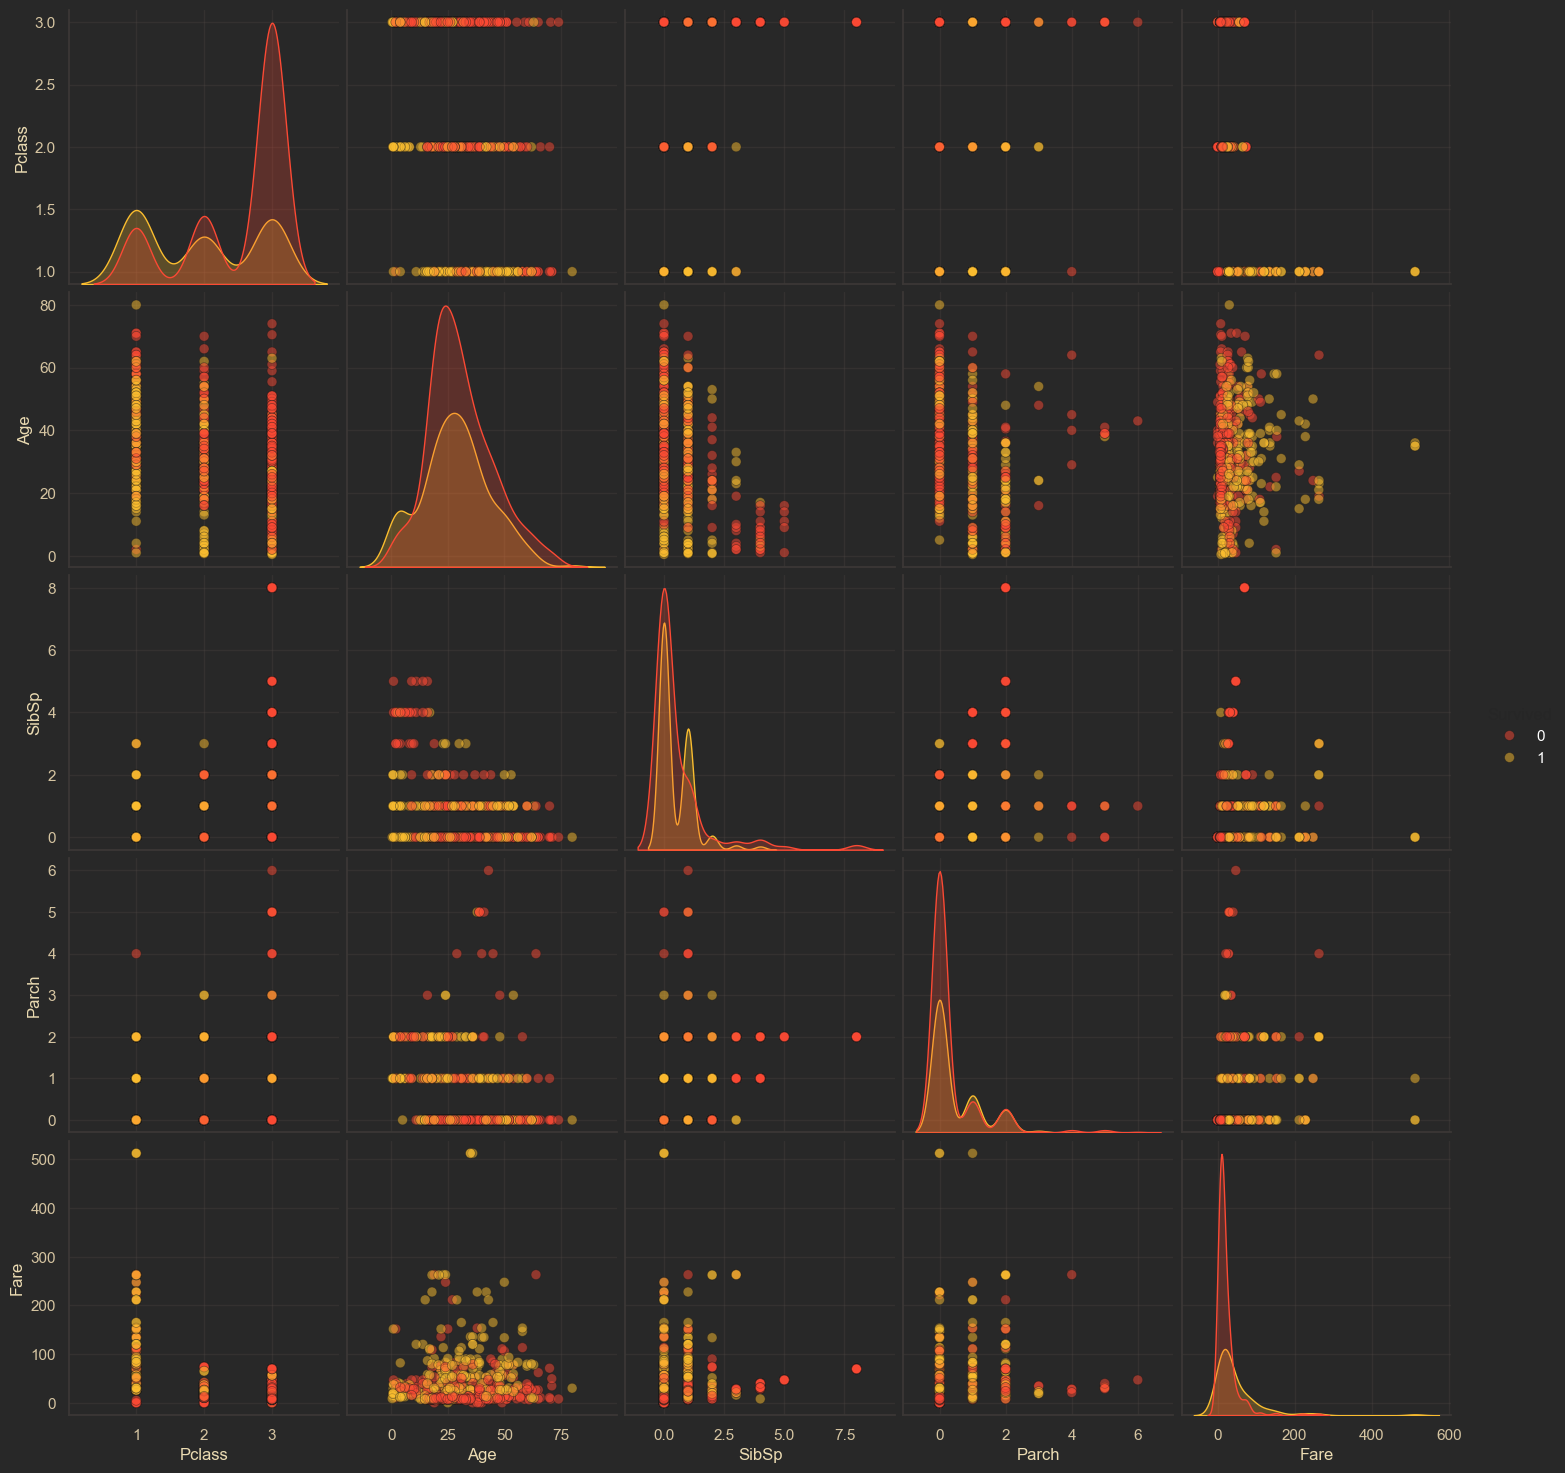

In [12]:
g = sns.pairplot(df_train_raw.drop('PassengerId',axis=1), hue='Survived', height=3, aspect=1, 
             plot_kws={'alpha':0.5, 's':50, 'edgecolor':'k', 'linewidth':0.5})
legend = g._legend
for text in legend.get_texts():
    text.set_color("white")

В ходе визуализации были сделаны следующие выводы:
* Признак pclass является одним из наиболее информативных для модели. Распределие ненормальное, многомодальное (что обусловлено 3-мя закодированными классами). Распределения по классам выживших значительно отличаются: пассажиры первого класса демонстрируют более высокую выживаемость, относительно пассажиров третьего класса.
* Распределение данных о возрасте говорит о большей смертности людей взрослого возраста, в сравнении с молодыми людьми (до 20 лет). Это может свидетельствовать о том, что основным таргетом для спасения преимущественно были дети.
* По распределнию признаков SibSp и Parch можно предположить, что одинокие люди спасались реже, чем супружеская пара или родственники. Пассажиры с более 5ью сиблингами на борту или другими членами семьи - не выжили.
* Признак Fare обладает высокой предсказательной силой: чем дороже билет был куплен, тем с большей вероятностью выживал человек.

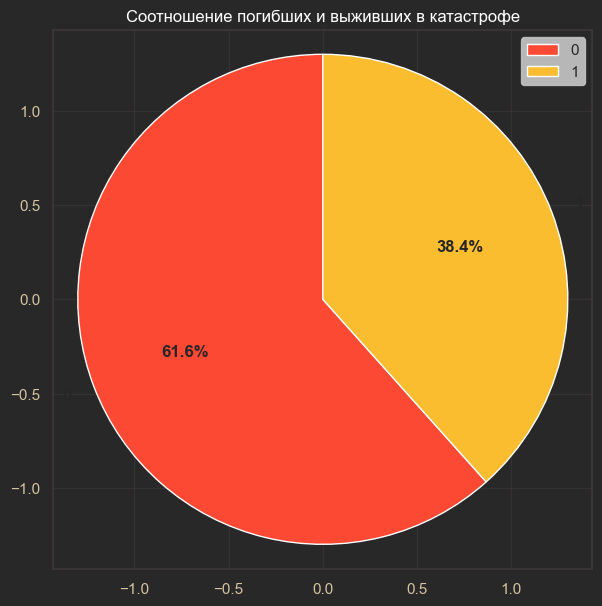

In [13]:
surv_val_counts = df_train_raw['Survived'].value_counts()
labels = surv_val_counts.index.tolist()
values = surv_val_counts.values

pie_charm(values,labels,title="Соотношение погибших и выживших в катастрофе")

Погибших примерно в 1.5 раза больше, чем выживших. Соотношение составляет:
* погибших - 61.6%
* выживших - 38.4%

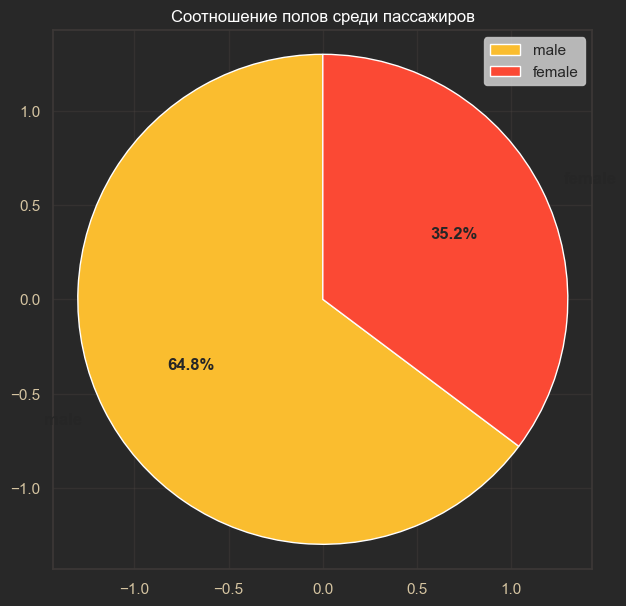

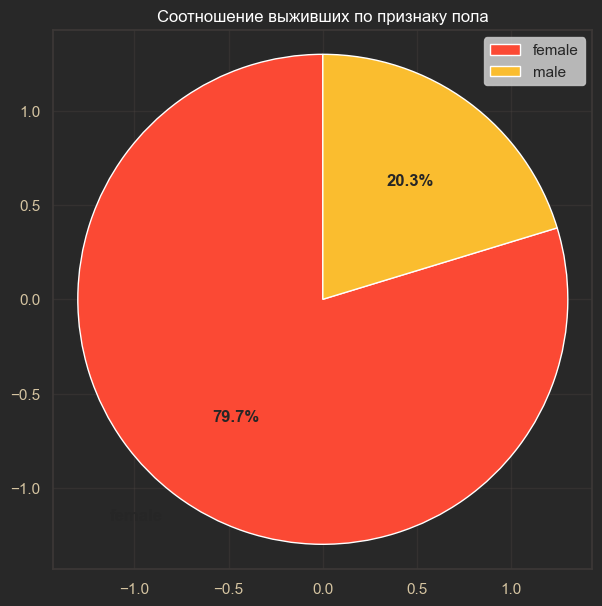

In [14]:
gender_vc = df_train_raw['Sex'].value_counts()
percent_gender = gender_vc.values
labels_gender = gender_vc.index.to_list()

pie_charm(percent_gender, labels_gender, title="Соотношение полов среди пассажиров",colors=[colorbox[1],colorbox[0]])

sex_surv = df_train_raw.groupby('Sex')['Survived'].mean()
percent_sex_surv = sex_surv.values
labels_sex_surv = sex_surv.index.to_list()

pie_charm(percent_sex_surv, labels_sex_surv,title="Соотношение выживших по признаку пола")

## Предобработка данных

**Создание копии датафреймов**

In [6]:
df_train = df_train_raw.copy()
df_test = df_test_raw.copy()

**Переименование столбцов**

In [7]:
df_train.columns = df_train.columns.str.lower()
df_train.columns

Index(['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp',
       'parch', 'ticket', 'fare', 'cabin', 'embarked'],
      dtype='object')

In [8]:
df_test.columns = df_test.columns.str.lower()
df_test.columns

Index(['passengerid', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch',
       'ticket', 'fare', 'cabin', 'embarked'],
      dtype='object')

Названия столбцов приведены к единому стилю.

## EDA

In [18]:
num_col = ['age', 'fare']
cat_col = ['sex','embarked','sibsp', 'parch','pclass']

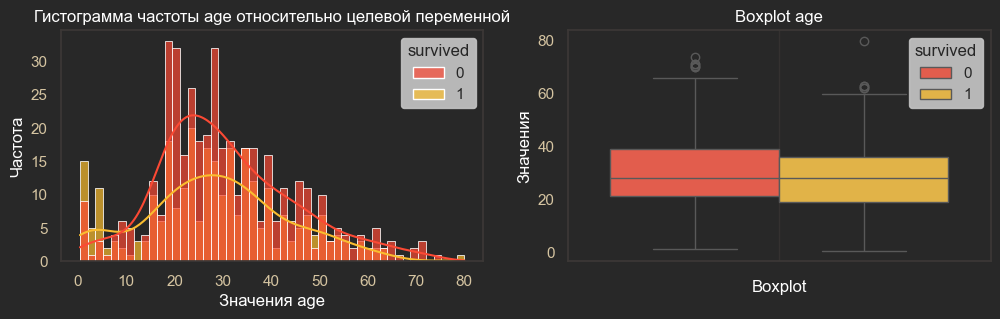

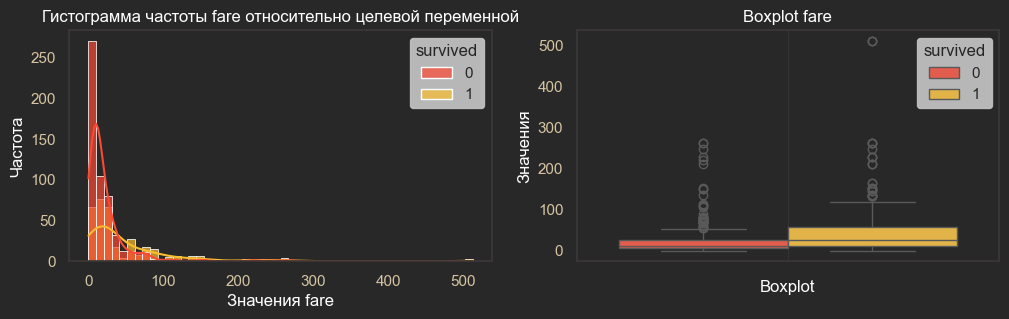

In [19]:
num_plot(df_train,num_col,figsize=(12,3))

In [20]:
df_train[num_col].describe()

,age,fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


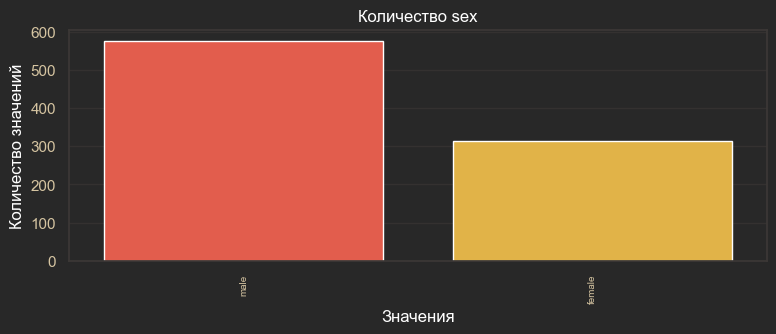

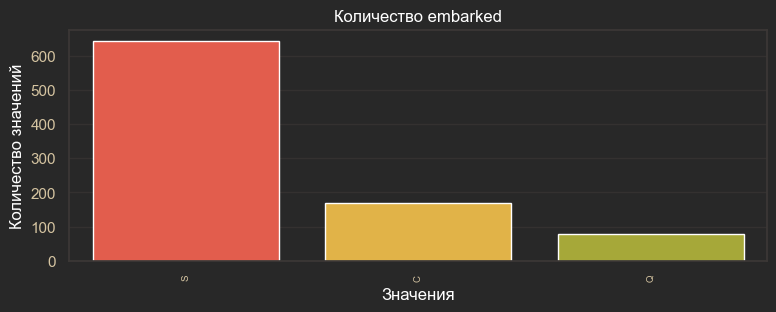

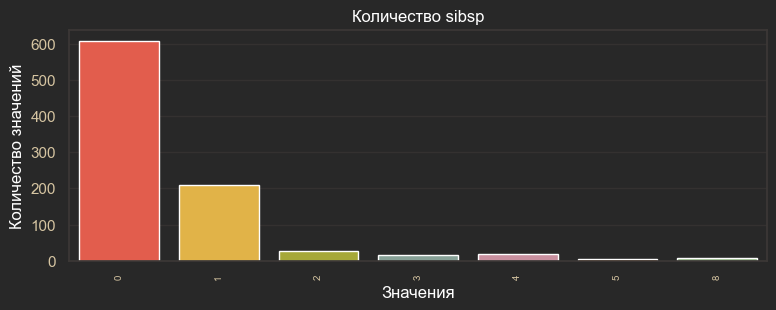

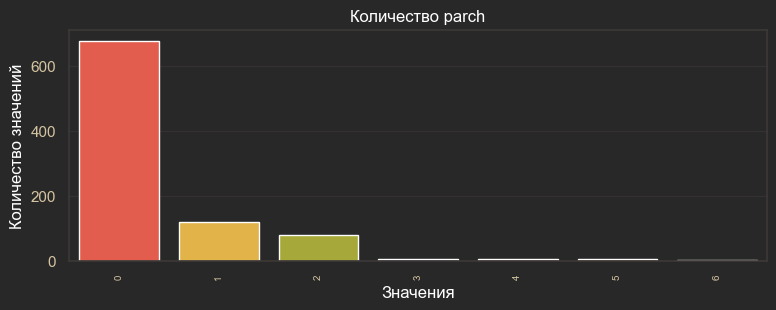

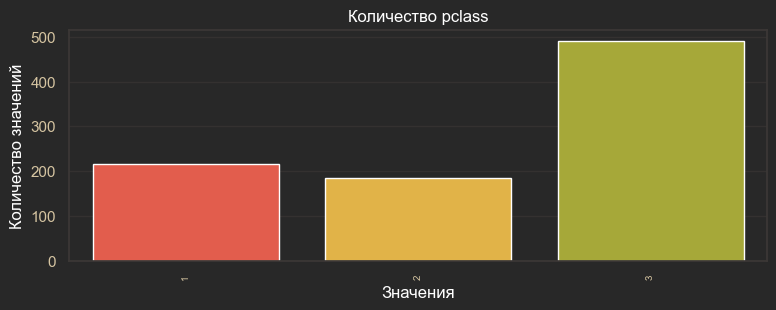

In [21]:
count_plot(df_train,cat_col)

In [22]:
for _ in cat_col:
    print(df_train[_].value_counts())
    print("\n")

sex
male      577
female    314
Name: count, dtype: int64


embarked
S    644
C    168
Q     77
Name: count, dtype: int64


sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64


parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


pclass
3    491
1    216
2    184
Name: count, dtype: int64




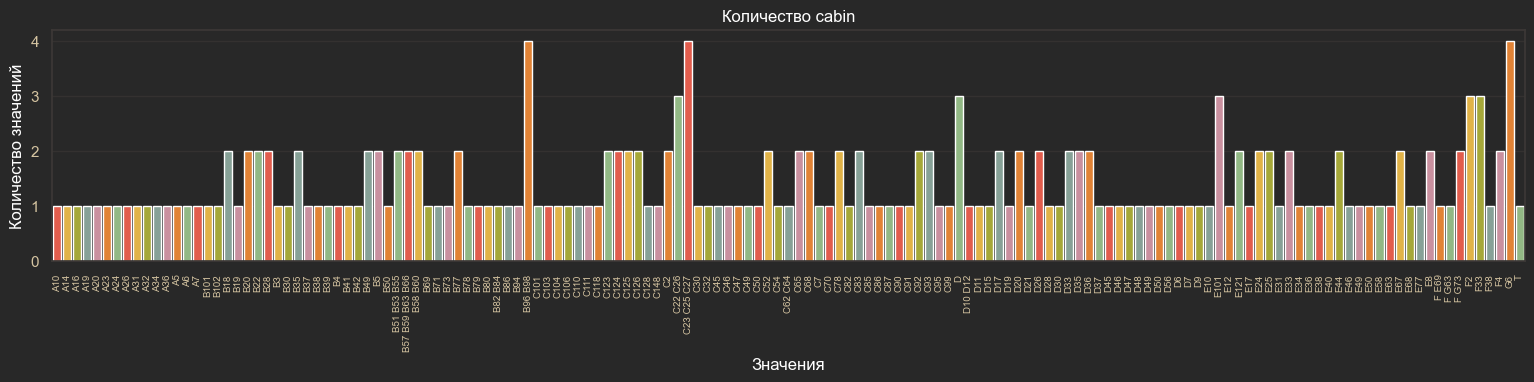

In [23]:
count_plot(df_train.sort_values('cabin'),['cabin'],figsize=(19,3),palette='tab20')

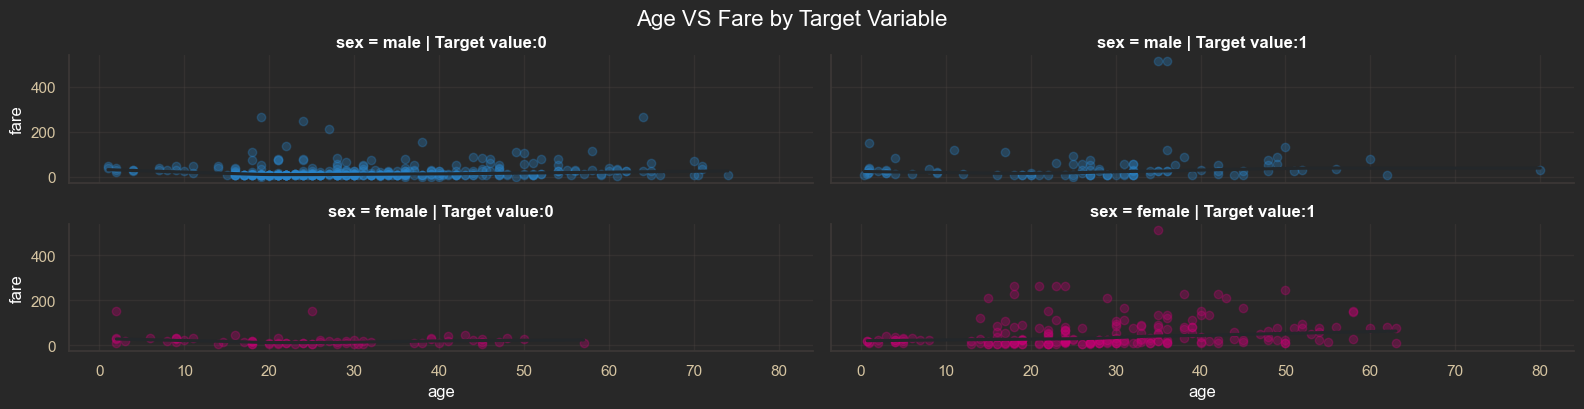

In [24]:
plotlm(x_var='age',y_var='fare',row_var='sex')

In [9]:
preproc_and_feature_engineering(df_train)
preproc_and_feature_engineering(df_test)

In [26]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   passengerid        891 non-null    int64   
 1   survived           891 non-null    int64   
 2   pclass             891 non-null    int64   
 3   name               891 non-null    object  
 4   sex                891 non-null    object  
 5   age                891 non-null    float64 
 6   sibsp              891 non-null    int64   
 7   parch              891 non-null    int64   
 8   ticket             891 non-null    object  
 9   fare               891 non-null    float64 
 10  cabin              204 non-null    object  
 11  embarked           891 non-null    object  
 12  title              891 non-null    object  
 13  cabin_location     891 non-null    object  
 14  cabin_count        891 non-null    int64   
 15  has_cabin          891 non-null    int32   
 16  age_cat 

In [27]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   passengerid        418 non-null    int64   
 1   pclass             418 non-null    int64   
 2   name               418 non-null    object  
 3   sex                418 non-null    object  
 4   age                418 non-null    float64 
 5   sibsp              418 non-null    int64   
 6   parch              418 non-null    int64   
 7   ticket             418 non-null    object  
 8   fare               418 non-null    float64 
 9   cabin              91 non-null     object  
 10  embarked           418 non-null    object  
 11  title              418 non-null    object  
 12  cabin_location     418 non-null    object  
 13  cabin_count        418 non-null    int64   
 14  has_cabin          418 non-null    int32   
 15  age_cat            418 non-null    category
 16  family_s

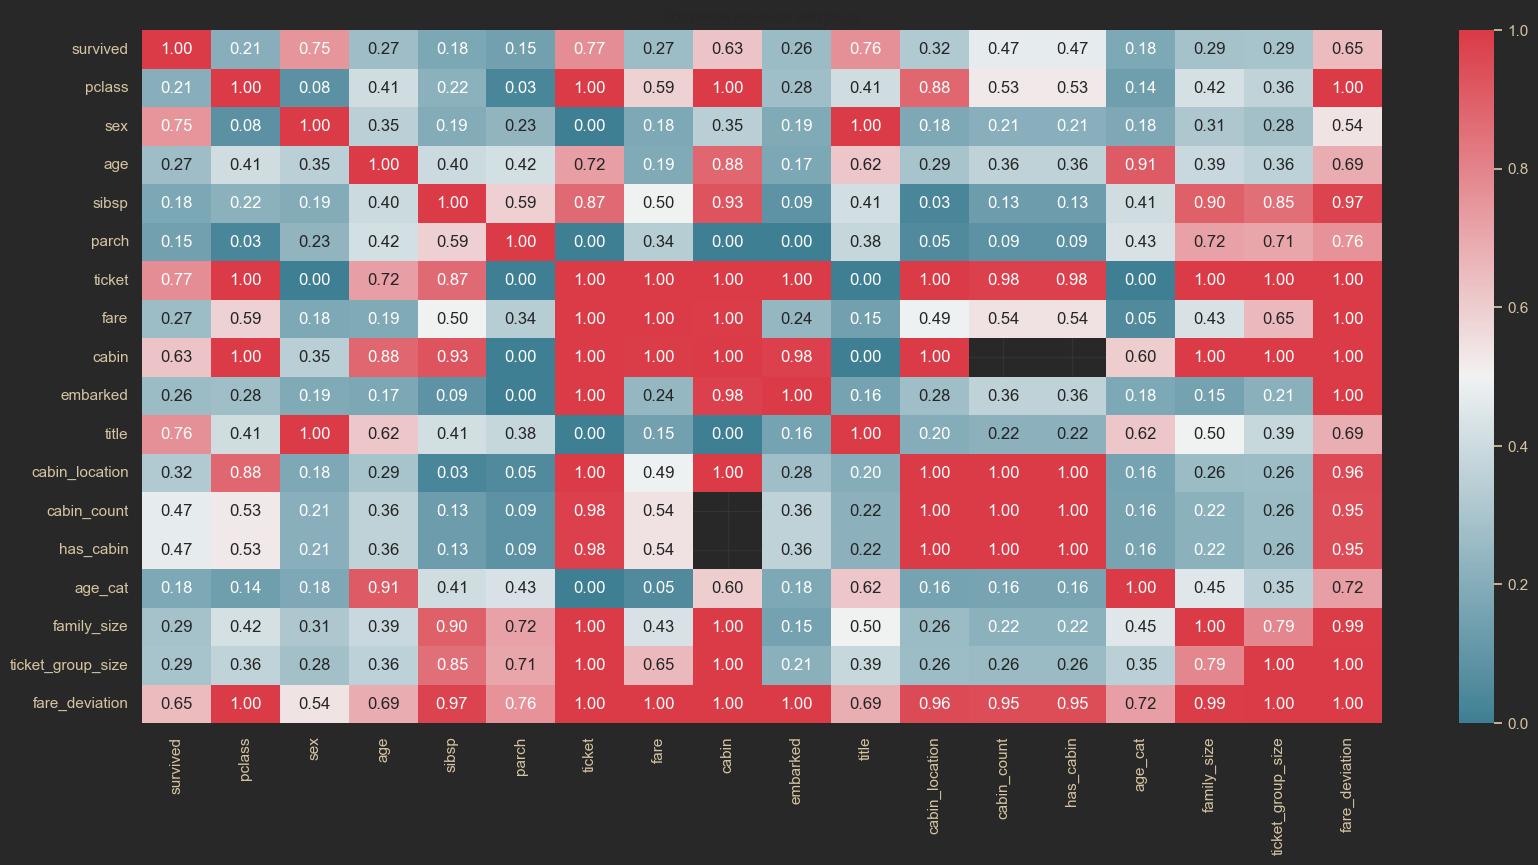

In [28]:
phik_corr = df_train.drop(['name','passengerid'], axis=1).phik_matrix(interval_cols=['age', 'fare'])

plt.figure(figsize=(20,9))
sns.heatmap(
    phik_corr,
    cmap = colormap,
    cbar = True,
    fmt = '.2f',
    annot = True
)
plt.title("Корреляционная матрица")
plt.show()

## Обучение модели

In [12]:
y = df_train['survived']
X = df_train.drop(['survived','passengerid', 'name', 'cabin'],axis=1)

X_train, X_valid, y_train, y_valid = train_test_split(X, y, random_state=RANDOM_STATE, test_size=TEST_SIZE)
X_test = df_test.drop(['passengerid', 'name', 'cabin'],axis=1)

In [30]:
X_train.columns

Index(['pclass', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'embarked',
       'title', 'cabin_location', 'cabin_count', 'has_cabin', 'age_cat',
       'family_size', 'ticket_group_size', 'fare_deviation'],
      dtype='object')

In [31]:
X_train.head()

,pclass,sex,age,sibsp,parch,ticket,fare,embarked,title,cabin_location,cabin_count,has_cabin,age_cat,family_size,ticket_group_size,fare_deviation
165,3,male,9.0,0,2,363291,20.5250,S,Master,U,0,0,Child,3,3,12.4750
541,3,female,9.0,4,2,347082,31.2750,S,Miss,U,0,0,Child,7,7,23.2250
625,1,male,61.0,0,0,36963,32.3208,S,Mr,D,1,1,Senior,1,1,-27.9667
388,3,male,30.0,0,0,367655,7.7292,Q,Mr,U,0,0,Adult,1,1,-0.3208
76,3,male,30.0,0,0,349208,7.8958,S,Mr,U,0,0,Adult,1,1,-0.1542


In [32]:
X_valid.head()

,pclass,sex,age,sibsp,parch,ticket,fare,embarked,title,cabin_location,cabin_count,has_cabin,age_cat,family_size,ticket_group_size,fare_deviation
709,3,male,3.5,1,1,2661,15.2458,C,Master,U,0,0,Child,3,2,7.1958
439,2,male,31.0,0,0,C.A. 18723,10.5000,S,Mr,U,0,0,Adult,1,1,-3.7500
840,3,male,20.0,0,0,SOTON/O2 3101287,7.9250,S,Mr,U,0,0,Adult,1,1,-0.1250
720,2,female,6.0,0,1,248727,33.0000,S,Miss,U,0,0,Child,2,3,18.7500
39,3,female,14.0,1,0,2651,11.2417,C,Miss,U,0,0,Teen,2,2,3.1917


In [13]:
ohe_col = ['sex','ticket', 'embarked', 'title', 'cabin_location','age_cat']
num_col = ['pclass', 'age', 'sibsp', 'parch', 'fare','cabin_count', 'has_cabin', 'family_size', 'ticket_group_size', 'fare_deviation']

In [14]:
ohe_pipe = Pipeline([
    ('SimpleImputer_bef_ohe',SimpleImputer(missing_values = np.nan,strategy = 'most_frequent')),
    ('ohe', OneHotEncoder(sparse_output = False ,handle_unknown='ignore',drop='first')),
    ('SimpleImputer_aft_ohe',SimpleImputer(missing_values = np.nan,strategy = 'most_frequent'))
])

data_preprocessor = ColumnTransformer([
    ('ohe', ohe_pipe, ohe_col),
    ('num', StandardScaler(), num_col)
],remainder='passthrough')


In [35]:
X_valid

,pclass,sex,age,sibsp,parch,ticket,fare,embarked,title,cabin_location,cabin_count,has_cabin,age_cat,family_size,ticket_group_size,fare_deviation
709,3,male,3.5,1,1,2661,15.2458,C,Master,U,0,0,Child,3,2,7.1958
439,2,male,31.0,0,0,C.A. 18723,10.5000,S,Mr,U,0,0,Adult,1,1,-3.7500
840,3,male,20.0,0,0,SOTON/O2 3101287,7.9250,S,Mr,U,0,0,Adult,1,1,-0.1250
720,2,female,6.0,0,1,248727,33.0000,S,Miss,U,0,0,Child,2,3,18.7500
39,3,female,14.0,1,0,2651,11.2417,C,Miss,U,0,0,Teen,2,2,3.1917
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,1,male,71.0,0,0,PC 17609,49.5042,C,Mr,U,0,0,Senior,1,1,-10.7833
215,1,female,31.0,1,0,35273,113.2750,C,Miss,D,1,1,Adult,2,3,52.9875
309,1,female,30.0,0,0,PC 17485,56.9292,C,Miss,E,1,1,Adult,1,2,-3.3583
822,1,male,38.0,0,0,19972,0.0000,S,Rare,U,0,0,Adult,1,1,-60.2875


In [15]:
X_train = data_preprocessor.fit_transform(X_train)
X_valid = data_preprocessor.transform(X_valid)
X_test = data_preprocessor.transform(X_test)

In [37]:
MLA = [
    LogisticRegression(),
    KNeighborsClassifier(),
    SVC(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    ExtraTreesClassifier(),
    GradientBoostingClassifier(),
    CatBoostClassifier(),
    LGBMClassifier(),
    XGBClassifier()
]


In [38]:
results = []

for model in MLA:
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        return_train_score=True,
        verbose=False
    )

    results.append({
        "Model": model.__class__.__name__,
        "Train_accuracy": scores["train_score"].mean(),
        "CV_accuracy": scores["test_score"].mean(),
        "CV_STD": round(scores["test_score"].std(),3)
    })

results_df = pd.DataFrame(results).sort_values("CV_accuracy",ascending=False).reset_index(drop=True)

Learning rate set to 0.008515
0:	learn: 0.6872328	total: 146ms	remaining: 2m 25s
1:	learn: 0.6820036	total: 149ms	remaining: 1m 14s
2:	learn: 0.6768633	total: 153ms	remaining: 50.9s
3:	learn: 0.6718493	total: 157ms	remaining: 39s
4:	learn: 0.6669744	total: 160ms	remaining: 31.9s
5:	learn: 0.6627524	total: 163ms	remaining: 27s
6:	learn: 0.6584400	total: 166ms	remaining: 23.5s
7:	learn: 0.6544918	total: 168ms	remaining: 20.9s
8:	learn: 0.6498998	total: 171ms	remaining: 18.8s
9:	learn: 0.6455447	total: 173ms	remaining: 17.2s
10:	learn: 0.6415393	total: 175ms	remaining: 15.8s
11:	learn: 0.6369521	total: 178ms	remaining: 14.7s
12:	learn: 0.6325049	total: 181ms	remaining: 13.7s
13:	learn: 0.6293574	total: 183ms	remaining: 12.9s
14:	learn: 0.6250984	total: 186ms	remaining: 12.2s
15:	learn: 0.6205807	total: 189ms	remaining: 11.6s
16:	learn: 0.6161405	total: 191ms	remaining: 11.1s
17:	learn: 0.6122274	total: 193ms	remaining: 10.6s
18:	learn: 0.6079548	total: 196ms	remaining: 10.1s
19:	learn: 0.

In [39]:
display(results_df)

,Model,Train_accuracy,CV_accuracy,CV_STD
0,LogisticRegression,0.886078,0.832640,0.031
1,CatBoostClassifier,0.898251,0.831405,0.025
2,ExtraTreesClassifier,0.998751,0.828921,0.018
3,RandomForestClassifier,0.998751,0.825155,0.026
4,SVC,0.851432,0.823898,0.034
5,GradientBoostingClassifier,0.869849,0.813983,0.014
6,DecisionTreeClassifier,0.998751,0.813944,0.015
7,KNeighborsClassifier,0.859236,0.801475,0.021
8,LGBMClassifier,0.963793,0.800225,0.014
9,XGBClassifier,0.980023,0.797733,0.013


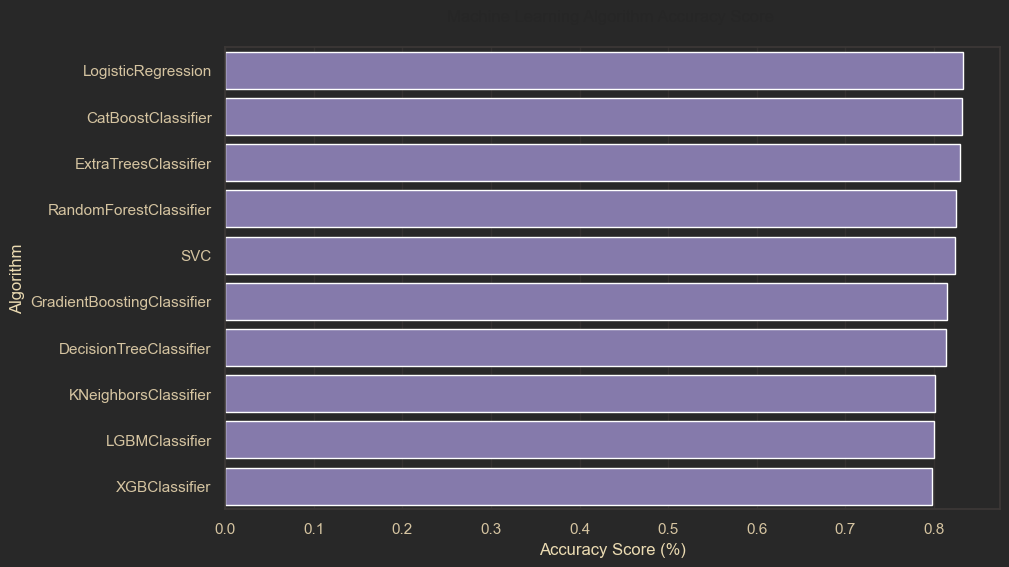

In [40]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=results_df,
    x="CV_accuracy",
    y="Model",
    orient="h",
    color = 'm'
)

plt.title('Machine Learning Algorithm Accuracy Score \n')
plt.xlabel('Accuracy Score (%)')
plt.ylabel('Algorithm')
plt.show()

Топ 5 лучших моделей:

1 ExtraTreesClassifier

2 LogisticRegression

3 CatBoostClassifier

4 RandomForestClassifier

5 SVC

In [41]:
std_accuracy_median = round(results_df['CV_STD'].median(),3)
print(f'Медианное значение CV_STD: {std_accuracy_median}')
results_df.loc[results_df['CV_STD'] > std_accuracy_median]

Медианное значение CV_STD: 0.02


,Model,Train_accuracy,CV_accuracy,CV_STD
0,LogisticRegression,0.886078,0.832640,0.031
1,CatBoostClassifier,0.898251,0.831405,0.025
3,RandomForestClassifier,0.998751,0.825155,0.026
4,SVC,0.851432,0.823898,0.034
7,KNeighborsClassifier,0.859236,0.801475,0.021


Потенциально большое значение std у моделей logisticRegression(0.027) и SVC(0.034), что может свидетельствовать о неоднородной точности предсказаний. Модель способна предсказывать больше ошибаться на определенных фолдах данных, что говорит о сильной чувствительности к набору данных и к определенным паттернам в них.

In [17]:
lm_param_grid = [
    {
        'penalty': ['l1', 'l2', 'elasticnet'],
        'C': [0.01, 0.1, 1, 10],
        'solver': ['liblinear', 'saga'],
        'l1_ratio': [0.1, 0.5, 0.9]
    }
]
            
lm_search = RandomizedSearchCV(
    LogisticRegression(random_state=RANDOM_STATE),
    lm_param_grid,
    cv=cv,
    scoring='accuracy',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    n_iter=10,
    verbose=2
)

lm_search.fit(X_train,y_train)
lm_best = lm_search.best_estimator_
print(f'Лучшая модель LogisticRegression в результате поиска гипперпараметров: {lm_best}')
print(f'Лучшая метрика кросс-валидации:{lm_search.best_score_}')

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Лучшая модель LogisticRegression в результате поиска гипперпараметров: LogisticRegression(C=10, l1_ratio=0.5, random_state=42, solver='liblinear')
Лучшая метрика кросс-валидации:0.8389130434782608


In [18]:
et_param_grid = [
    {
        'n_estimators': [100,200,300,500,800],
        'max_depth': [2,3,4,5],
        'min_samples_leaf': [1, 2, 5, 10, 20, 50],
        'min_samples_split': [5,10,15,30,60,100],
        'max_features': ['sqrt', 'log2', 0.3, 0.5]
    }
]
            
et_search = RandomizedSearchCV(
    ExtraTreesClassifier(random_state=RANDOM_STATE),
    et_param_grid,
    cv=cv,
    scoring='accuracy',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    n_iter=15,
    verbose=2
)

et_search.fit(X_train,y_train)
et_best = et_search.best_estimator_
print(f'Лучшая модель в результате поиска гипперпараметров: {et_best}')
print(f'Лучшая метрика кросс-валидации:{et_search.best_score_}')

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Лучшая модель в результате поиска гипперпараметров: ExtraTreesClassifier(max_depth=3, max_features=0.5, min_samples_leaf=2,
                     min_samples_split=5, n_estimators=800, random_state=42)
Лучшая метрика кросс-валидации:0.8276863354037267


In [19]:
cb_param_grid = [{
    'iterations': [200, 400, 800, 1000],
    'depth': [2, 3, 4, 5, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'min_child_samples': [1, 5, 10, 20, 50],
    'subsample': [0.6, 0.8, 1.0],
    'border_count': [32, 64, 128]
}]
            
cb_search = RandomizedSearchCV(
    CatBoostClassifier(random_state=RANDOM_STATE),
    cb_param_grid,
    cv=cv,
    scoring='accuracy',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    n_iter=10,
    verbose=2
)
cb_search.fit(X_train,y_train)
cb_best = cb_search.best_estimator_
print(f'Лучшая модель CatBoost в результате поиска гипперпараметров: {cb_best}')
print(f'Лучшая метрика кросс-валидации:{cb_search.best_score_}')

Fitting 5 folds for each of 10 candidates, totalling 50 fits
0:	learn: 0.6868901	total: 146ms	remaining: 58.1s
1:	learn: 0.6820628	total: 147ms	remaining: 29.3s
2:	learn: 0.6753984	total: 152ms	remaining: 20.1s
3:	learn: 0.6685103	total: 162ms	remaining: 16s
4:	learn: 0.6620798	total: 172ms	remaining: 13.6s
5:	learn: 0.6565110	total: 181ms	remaining: 11.9s
6:	learn: 0.6502436	total: 191ms	remaining: 10.7s
7:	learn: 0.6448562	total: 201ms	remaining: 9.84s
8:	learn: 0.6393944	total: 207ms	remaining: 9s
9:	learn: 0.6343380	total: 212ms	remaining: 8.26s
10:	learn: 0.6289979	total: 221ms	remaining: 7.82s
11:	learn: 0.6250495	total: 226ms	remaining: 7.3s
12:	learn: 0.6199550	total: 236ms	remaining: 7.02s
13:	learn: 0.6152573	total: 246ms	remaining: 6.77s
14:	learn: 0.6111238	total: 250ms	remaining: 6.41s
15:	learn: 0.6066475	total: 259ms	remaining: 6.21s
16:	learn: 0.6023564	total: 269ms	remaining: 6.05s
17:	learn: 0.5980213	total: 278ms	remaining: 5.91s
18:	learn: 0.5944561	total: 282ms	rem

In [20]:
svc_param_grid = {
    'kernel': ['rbf', 'poly', 'sigmoid'],
    'C': [0.01, 0.1, 1, 5, 10, 50],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
    'degree': [2, 3, 4],  # используется только для poly
    'class_weight': [None, 'balanced']
}

svc_search = RandomizedSearchCV(
    SVC(probability=True, random_state=RANDOM_STATE),
    svc_param_grid,
    cv=cv,
    scoring='accuracy',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    n_iter=10,
    verbose=2
)
svc_search.fit(X_train,y_train)
svc_best = svc_search.best_estimator_
print(f'Лучшая модель CatBoost в результате поиска гипперпараметров: {svc_best}')
print(f'Лучшая метрика кросс-валидации:{svc_search.best_score_}')

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Лучшая модель CatBoost в результате поиска гипперпараметров: SVC(C=10, class_weight='balanced', degree=2, gamma=0.1, kernel='poly',
    probability=True, random_state=42)
Лучшая метрика кросс-валидации:0.836389751552795


In [21]:
rf_param_grid = {
    'n_estimators': [200, 400, 800, 1000],
    'max_depth': [None, 3, 5, 8, 12],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=rf_param_grid,
    n_iter=20,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=2,
    random_state=42
)

rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_
print(f'Лучшая модель RandomForest в результате поиска гипперпараметров: {rf_best}')
print(f'Лучшая метрика кросс-валидации:{rf_search.best_score_}')

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Лучшая модель RandomForest в результате поиска гипперпараметров: RandomForestClassifier(max_depth=5, max_features=None, n_estimators=800,
                       random_state=42)
Лучшая метрика кросс-валидации:0.8239596273291925


In [22]:
lgb_param_grid = {
    'n_estimators': [200, 400, 800, 1000],
    'max_depth': [2, 3, 4, 5, 8, 12],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 63, 127],
    'min_child_samples': [5, 10, 20, 50],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

lgb_search = RandomizedSearchCV(
    estimator=LGBMClassifier(random_state=RANDOM_STATE),
    param_distributions=lgb_param_grid,
    n_iter=20,                 # количество случайных комбинаций
    scoring='accuracy',         # метрика
    cv=5,
    n_jobs=-1,
    verbose=2,
    random_state=42
)

lgb_search.fit(X_train, y_train)
lgb_best = lgb_search.best_estimator_
print(f"Лучшая модель LGBM в результате поиска гипперпараметров: {lgb_best}")
print(f"Лучшая метрика кросс-валидации: {lgb_search.best_score_}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[LightGBM] [Info] Number of positive: 306, number of negative: 495
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000398 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 397
[LightGBM] [Info] Number of data points in the train set: 801, number of used features: 26
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.382022 -> initscore=-0.480973
[LightGBM] [Info] Start training from score -0.480973
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

In [10]:
stack = StackingClassifier(
    estimators=[
        #Топ6 моделей по метрике
        ("lm", lm_best),
        ("rf", rf_best),
        ("et", et_best),
        ("lgbm", lgb_best),
        ("svc", svc_best),
        ("cb", cb_best),
        #KNN - геометрический эксперт
        ("knn", KNeighborsClassifier(
            n_neighbors=15,           # не слишком локально, не слишком глобально
            weights='distance',       # ближайшие соседи важнее
            metric='euclidean',
            n_jobs=-1                 # параллелим
        )),
        
        #LightGBM СИЛЬНЫЙ - ловит сложные паттерны
        ("lgbm_strong", LGBMClassifier(
            n_estimators=2000,        # много деревьев
            learning_rate=0.01,       # маленький шаг
            max_depth=8,              # глубокие деревья
            num_leaves=127,           # много листьев для сложных правил
            subsample=0.8,            # bagging
            colsample_bytree=0.8,     # feature sampling
            reg_alpha=0.1,            # L1 регуляризация
            reg_lambda=0.3,           # L2 регуляризация
            min_child_samples=20,     # защита от переобучения
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )),
        
        #LightGBM СЛАБЫЙ - ловит базовые тренды
        ("lgbm_low", LGBMClassifier(
            n_estimators=100,         # мало деревьев
            learning_rate=0.1,        # большой шаг (быстрее сходится)
            max_depth=3,              # неглубокие деревья (простые правила)
            num_leaves=8,             # мало листьев
            subsample=1.0,            # без bagging (больше bias)
            colsample_bytree=1.0,     # все признаки
            reg_alpha=0.0,            # без регуляризации
            reg_lambda=0.0,
            min_child_samples=1,      # минимальное разделение
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )),
        
        #XGBoost СИЛЬНЫЙ - альтернативный сильный бустинг
        ("xgb_strong", XGBClassifier(
            n_estimators=2000,
            learning_rate=0.01,
            max_depth=8,
            min_child_weight=3,       # защита от переобучения
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            gamma=0.1,                # минимальное уменьшение loss для split
            tree_method='hist',       # быстрее, меньше памяти
            use_label_encoder=False,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        )),
        
        #XGBoost СЛАБЫЙ - альтернативный простой бустинг
        ("xgb_low", XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,              # stumps почти
            min_child_weight=1,
            subsample=1.0,
            colsample_bytree=1.0,
            reg_alpha=0.0,
            reg_lambda=0.0,
            gamma=0.0,
            tree_method='exact',      # точный метод для простых деревьев
            use_label_encoder=False,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=RidgeClassifier(alpha=0.1),
    cv=cv,
    n_jobs=-1
)

stack.fit(X_train, y_train)
valid_pred = stack.predict(X_valid)
print(f"Метрика accuracy на валидационных данных: {accuracy_score(valid_pred,y_valid)}")

NameError: name 'lm_best' is not defined

In [55]:
stack_preds = stack.predict(X_test)

In [56]:
submission = pd.DataFrame({
    'PassengerId': df_test['passengerid'],
    'Survived': stack_preds
})

submission.head()

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [57]:
csv_path = 'datasets/titanic/submission.csv'
submission.to_csv(csv_path, index=False)

shutil.make_archive(
    base_name='submission',
    format='zip',
    root_dir='datasets/titanic',
    base_dir='submission.csv'
)

'C:\\Users\\user\\submission.zip'